# ViZDoom Defend the Line: PPO with AgileRL

In this notebook, we're going to train a PPO agent to beat the Defend the Line scenario in ViZDoom, using only visual observations from the game!

This notebook won't be going over RL as a whole, more just how to use AgileRL for a PPO run on Defend the Line.

We'll be using the AgileRL library for our PPO implementation. AgileRL is built for population-based training, but a single agent works just as well, and it's easy to pick up and extend. It ships with DQN, Rainbow, and PPO, and in my experience it converges faster than Stable Baselines3 in experiments like this one. That makes it perfect for quick tests!

Defend the Line puts Doomguy at one end of a room, facing imps that throw fireballs and demons that charge. Every enemy comes back tougher after it dies, and all he can do is turn and shoot! The official writeup of the scenario is [here](https://vizdoom.farama.org/environments/default/#defend-the-line).

One twist: training uses the stock scenario, but evaluation and recording use `defend_the_line_outro`, a version I made so the episode doesn't end the instant Doomguy dies. This lets the death animation make it into the video, weapon drop and all, instead of cutting straight to black. This is optional however, and the notebook should be robust enough so that it doesn't crash if it can't find it.

Similarly it also tries to use the original Doom WADs if it can find them.

The notebook was designed to run in place in the repo, however it also supports running on Google Colab, with the option of using Google Drive to save artifacts.


# Setup
First, we'll install the dependencies and load the imports.

Install the pinned dependencies first.

In [1]:
import sys

# Update the required system packages when running on Colab.
if "google.colab" in sys.modules:
    !apt-get update -qq
    !apt-get install -y -qq libopenal1 libopenal-dev > /dev/null

# Install the Python packages used throughout the notebook.
%pip install -q vizdoom==1.3.1 agilerl==2.8.4 gymnasium==1.3.0 imageio==2.38.0 imageio-ffmpeg==0.6.0 opencv-python==5.0.0.93 scipy==1.17.1 numpy==2.4.6 pandas==3.0.5 torch==2.13.0 matplotlib==3.11.1


Note: you may need to restart the kernel to use updated packages.


# Imports
Next, import everything used throughout the notebook.

In [2]:
import json
import os
import shutil
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import gymnasium
import imageio.v2 as imageio
import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


from agilerl.algorithms.ppo import PPO
from agilerl.training.train_on_policy import train_on_policy
from gymnasium.spaces import Box
from gymnasium.wrappers import FrameStackObservation, ResizeObservation, TransformObservation
from IPython.display import Image, display
from scipy.io import wavfile


import vizdoom as vzd
from vizdoom import gymnasium_wrapper  # registers the Vizdoom* gymnasium envs
from vizdoom.gymnasium_wrapper.base_gymnasium_env import VizdoomEnv

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Experiment Setup
The observation setup matches the other notebooks. The agent acts every 4 frames and sees the last 4 frames stacked at 84x84, which gives it a sense of motion. Defend the Line has 3 buttons, turn left, turn right, and attack, and we allow up to 2 at once so it can turn and shoot together. That comes out to 7 actions. We run 16 environments side by side, which PPO likes, because every update learns from a fresh batch collected across all of them.

`DAMAGE_PENALTY` controls the reward shaping. `EVAL_EPISODES` scores each checkpoint. `RECORD_EPISODES` is how many videos we save. Set `RECORD_CHECKPOINTS` to `"all"` if you want every generation, although converting all of them takes a while.


In [3]:
ENV_NAME = "VizdoomDefendLine-v1"
NUM_ENVS = 16
FRAME_SKIP = 4          # act every 4 frames
STACK_SIZE = 4          # last 4 frames, so the agent can see motion
OBS_SIZE = (84, 84)
MAX_BUTTONS_PRESSED = 2 # up to 2 buttons at once
DAMAGE_PENALTY = 0.01  # penalty per point of health lost

EVAL_EPISODES = 4
RECORD_EPISODES = 3
RECORD_CHECKPOINTS = "best"  # or "all"


All the path logic lives in the next few cells, so the rest of the notebook doesn't need to care whether it's running on Colab or locally.

On Colab, `USE_DRIVE` keeps the run in Google Drive so it survives the session. Otherwise, everything stays in the notebook's folder.

In [4]:
USE_DRIVE = True # Colab only: keep the experiment (and every output) in Google Drive
EXPERIMENT = "defend-the-line-ppo-AgileRL"

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    experiment_dir = Path("/content/drive/MyDrive/rl-epsilon/vizdoom-agilerl-experiments") / EXPERIMENT
elif "google.colab" in sys.modules:
    experiment_dir = Path("/content") / EXPERIMENT  # lost when the Colab session ends
else:
    experiment_dir = Path.cwd()  # local: the notebook's own folder
print("experiment:", experiment_dir)


experiment: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-line-ppo-AgileRL


ViZDoom ships with Freedoom. But if `DOOM2.WAD` is in the `WADS` folder, we use that instead. Always better to use the original assets in my opinion! The scenario follows the same fallback pattern: `defend_the_line_outro` lets the death animation play, but if that file isn't available, we use the stock scenario.

In [5]:
USE_DOOM2_WAD = True  # use DOOM2.WAD if found, otherwise ViZDoom's bundled Freedoom
SCENARIO = "defend_the_line_outro.cfg"   # custom scenario in scenario_files/
STOCK_SCENARIO = "defend_the_line.cfg"  # bundled with ViZDoom, used if the custom one is missing

custom_cfg = experiment_dir / "scenario_files" / SCENARIO
scenario_cfg = str(custom_cfg if custom_cfg.is_file() else Path(vzd.scenarios_path) / STOCK_SCENARIO)
SCENARIO_NAME = Path(scenario_cfg).stem

wad = experiment_dir.parent / "WADS" / "DOOM2.WAD"
DOOM_WAD = str(wad) if USE_DOOM2_WAD and wad.is_file() else None
IWAD_NAME = Path(DOOM_WAD).name if DOOM_WAD else "freedoom2"
print("scenario:", scenario_cfg)
print("IWAD:", IWAD_NAME)

scenario: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-line-ppo-AgileRL/scenario_files/defend_the_line_outro.cfg
IWAD: DOOM2.WAD


Each run gets its own timestamped folder. The best model, charts, and videos are copied to `artifacts`.

In [6]:
run_dir = experiment_dir / "training-runs" / f"run-{datetime.now():%Y%m%d_%H%M%S}"
checkpoint_dir = run_dir / "checkpoints"
recording_dir = run_dir / "recordings"
artifacts_dir = experiment_dir / "artifacts"
model_dir = artifacts_dir / "model"
video_dir = artifacts_dir / "video"
figure_dir = artifacts_dir / "plots_and_figures"
for d in (checkpoint_dir, recording_dir, model_dir, video_dir, figure_dir):
    d.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "PPO.pt"
best_model_path = model_dir / "best_model.pt"
metrics_csv = figure_dir / "generation_metrics.csv"
results_path = artifacts_dir / "results.json"
print("run:", run_dir.name)

run: run-20261020_195949


# Environment
Next, we'll build the environment used to train Doomguy.

He stands at one end of a rectangular room, facing three imps that stay put and throw fireballs, and three demons that charge. Each enemy respawns a few seconds after it dies, with more health every time, so surviving longer makes the room harder. Like Defend the Center, he can only turn and fire, but at least everything starts in front of him. The scenario keeps topping up his ammo.

A kill is +1 and dying is -1. Unlike the other scenarios, there's no time limit. The episode ends only when he dies, so staying alive matters as much as shooting.

Ammo never runs out, so there's no point penalizing shots. The stock reward only notices damage once he's dead, which is a long time to wait. `RewardWrapper` subtracts `DAMAGE_PENALTY` for every point of health lost, which nudges the agent to deal with the demons before they arrive and the imps before the fireballs add up. It reads health and the kill count straight from the game.

In [7]:
class RewardWrapper(gymnasium.Wrapper):
    """Subtracts DAMAGE_PENALTY per point of health lost."""

    def _read(self):
        game = self.env.unwrapped.game
        return game.get_game_variable(vzd.GameVariable.HEALTH), game.get_game_variable(vzd.GameVariable.KILLCOUNT)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.health, self.kills = self._read()
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        health, self.kills = self._read()
        reward -= DAMAGE_PENALTY * max(0, self.health - health)
        self.health = health
        return obs, reward, terminated, truncated, info

`preprocess_env` turns each frame into an 84x84 grayscale image and stacks the last 4. Unlike Deadly Corridor, there's no need to scale the reward, since kills and deaths are already worth 1. The shaping gets added on top.

In [8]:
def preprocess_env(env):
    h, w, _ = env.observation_space["screen"].shape
    env = TransformObservation(
        env,
        lambda obs: (obs["screen"] @ np.array([0.299, 0.587, 0.114])).astype(np.uint8),
        Box(low=0, high=255, shape=(h, w), dtype=np.uint8),
    )  # grayscale
    env = ResizeObservation(env, OBS_SIZE)  # 84x84
    env = FrameStackObservation(env, stack_size=STACK_SIZE)  # last 4 frames
    return RewardWrapper(env)


`make_env` uses the stock scenario for training. For evaluation and recording we pass in the outro file, so the death animation has time to play.

In [9]:
def make_env(config_file=None):
    """Stock scenario for training. Pass a config file for eval and recording."""
    kwargs = dict(
        render_mode="rgb_array",
        frame_skip=FRAME_SKIP,
        screen_resolution=vzd.ScreenResolution.RES_200X125,
        max_buttons_pressed=MAX_BUTTONS_PRESSED,
        treat_episode_timeout_as_truncation=False,
    )
    if DOOM_WAD:
        kwargs["doom_game_path"] = DOOM_WAD
    env = VizdoomEnv(config_file=config_file, **kwargs) if config_file else gymnasium.make(ENV_NAME, **kwargs)
    return preprocess_env(env)


We then create `NUM_ENVS` copies, each in its own process, so they can step at the same time.

In [10]:
env = gymnasium.vector.AsyncVectorEnv(
    [make_env] * NUM_ENVS, autoreset_mode=gymnasium.vector.AutoresetMode.SAME_STEP
)

objc[24380]: Class SDLApplication is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11bf78a68) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x124584890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[24380]: Class SDLAppDelegate is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11bf78ab8) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x1245848e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[24380]: Class SDLTranslatorResponder is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11bf78b30) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x124584958). This may cause spurio

# Agent
Now we'll build the PPO agent. It learns the policy directly, as a probability for each action, instead of scoring actions and picking the best one. It collects a fresh batch, takes a few careful updates, then throws the batch away. No replay buffer, and no epsilon schedule.

PPO collects `LEARN_STEP` steps of fresh experience, 2048 in total, or 128 from each of the 16 environments. It then makes `UPDATE_EPOCHS` passes over that batch in chunks of `BATCH_SIZE` and throws the batch away. `CLIP_COEF` is what puts the proximal in PPO: it limits how far one update can move the policy away from the policy that collected the data. `ENT_COEF` adds a small bonus for keeping the action probabilities spread out, so the agent doesn't lock onto one action too early. These are pretty standard starting values for PPO on pixel games. We train for about 2,000,000 steps. Every 25 updates, 51,200 steps, make up one generation: AgileRL evaluates one episode in each of the 16 environments and we save a checkpoint, which gives us 40 to compare.

In [11]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"  # Apple Silicon GPU
else:
    device = "cpu"

INIT_HP = {
    "BATCH_SIZE": 256,
    "LR": 2.5e-4,
    "GAMMA": 0.99,             # how much future reward counts
    "GAE_LAMBDA": 0.95,        # how far ahead the advantage looks
    "LEARN_STEP": 2048,        # fresh steps across all envs before an update
    "UPDATE_EPOCHS": 4,        # passes over that batch
    "CLIP_COEF": 0.1,          # how far one update can move the policy
    "ENT_COEF": 0.01,          # bonus for keeping actions spread out
    "VF_COEF": 0.5,            # weight of the value loss
    "MAX_GRAD_NORM": 0.5,      # gradient clipping
    "MAX_STEPS": 2_048_000,
    "EVO_STEPS": 51_200,       # steps per generation, 25 updates
    "EVAL_LOOP": 1,            # one episode in each env at the end of a generation
    "CHECKPOINT": 51_200,      # one checkpoint per generation, 40 total
}


The network follows the original Atari DQN design: three convolutional layers, then a 256-unit hidden layer. PPO actually has two heads. The actor picks actions, and the critic estimates how well things are going so the actor can tell whether an action beat expectations. AgileRL has them share the convolutional layers by default.

In [12]:
net_config = {
    "encoder_config": {"channel_size": [32, 64, 64], "kernel_size": [8, 4, 3], "stride_size": [4, 2, 1]},  # 3 conv layers
    "head_config": {"hidden_size": [256]},  # smaller than the original Atari head
}


There's no replay buffer this time. PPO keeps its own rollout buffer for the current batch, which is why we pass `num_envs`.

In [13]:
ppo_agent = PPO(
    observation_space=env.single_observation_space,
    action_space=env.single_action_space,
    net_config=net_config,
    batch_size=INIT_HP["BATCH_SIZE"],
    lr=INIT_HP["LR"],
    learn_step=INIT_HP["LEARN_STEP"],
    gamma=INIT_HP["GAMMA"],
    gae_lambda=INIT_HP["GAE_LAMBDA"],
    update_epochs=INIT_HP["UPDATE_EPOCHS"],
    clip_coef=INIT_HP["CLIP_COEF"],
    ent_coef=INIT_HP["ENT_COEF"],
    vf_coef=INIT_HP["VF_COEF"],
    max_grad_norm=INIT_HP["MAX_GRAD_NORM"],
    num_envs=NUM_ENVS,
    device=device,
)

/opt/miniconda3/lib/python3.13/site-packages/tensordict/_td.py:612: FutureWarning: TensorDict.to_module() is replacing an existing nn.Parameter in the destination module with a tensor leaf that is not an nn.Parameter. This historical behavior can remove the key from module.state_dict(). In tensordict v0.14, to_module() will preserve existing module parameter and buffer registrations by default. Pass preserve_module_state=False to keep the current replacement behavior, or preserve_module_state=True to opt in to the v0.14 behavior now.
  local_out = _set_tensor_dict(


We'll use the same small hack as the DQN notebooks to gather metrics during training. By wrapping the agent's test function, we can preserve values that AgileRL would otherwise clear. PPO tracks a few more of them: separate actor and critic losses, plus the entropy of the policy.

Two quirks need fixing while we're here. AgileRL logs entropy as a loss, which is just the entropy with the sign flipped, so we flip it back. And when it averages these metrics it divides by the number of samples instead of the number of minibatches, so they come out `BATCH_SIZE` times too small. Multiplying by the batch size gets the real averages.

In [14]:
history = []
_test = PPO.test.__get__(ppo_agent)


def test_and_log(*args, **kwargs):
    m = ppo_agent.metrics  # read before train_on_policy clears it
    scale = ppo_agent.batch_size  # AgileRL averages over samples, so this puts the mean back
    row = {
        "steps": m.steps,
        "loss": scale * m.get_mean("loss"),
        "policy_loss": scale * m.get_mean("policy_loss"),
        "value_loss": scale * m.get_mean("value_loss"),
        "entropy": -scale * m.get_mean("entropy_loss"),
        "train_score": np.mean(m.scores) if m.scores else np.nan,
    }
    row["eval_fitness"] = _test(*args, **kwargs)
    history.append(row)
    return row["eval_fitness"]


ppo_agent.test = test_and_log


# Training
There's no epsilon schedule this time. PPO explores by sampling from its own policy. A run this long is a good time to step away from the machine. `verbose=False` prevents AgileRL from printing a metrics table after every generation and breaking up the progress bar; we're already recording the losses ourselves.

In [15]:
train_on_policy(
    env=env,
    env_name=ENV_NAME,
    algo="PPO",
    pop=[ppo_agent],
    init_hp=INIT_HP,
    max_steps=INIT_HP["MAX_STEPS"],
    evo_steps=INIT_HP["EVO_STEPS"],
    eval_loop=INIT_HP["EVAL_LOOP"],
    checkpoint=INIT_HP["CHECKPOINT"],
    checkpoint_path=str(checkpoint_path),
    verbose=False,  # the per-generation table breaks up the progress bar in notebooks
)
env.close()

Training Progress │ 100% │ ████████████████████ │ 2048000/2048000 steps │ ⏱️ 44:07 │ ⏳ 00:00 │ 773.47step/s


# Evaluation
During training AgileRL does do an evaluation step where it saves a checkpoint and runs a few episodes on the stock scenario to score the generation, but I decided to go ahead and include a full evaluation loop on all generations by reloading each checkpoint. That makes it easier to score them on the outro scenario, where the death animation gets to play.


`load_agent` loads a checkpoint, while `play` runs one episode and returns its total reward, actions, and anything else we asked it to track. One difference from DQN: AgileRL still samples from the PPO policy when the agent isn't training. We keep that, because that's the policy PPO learned, and always taking the single most likely action can leave it stuck repeating itself.

In [16]:
def load_agent(path):
    agent = PPO.load(str(path), device=device)
    agent.set_training_mode(False)
    return agent


def play(env, agent, obs):
    """Run one episode from `obs`; returns (total_reward, actions)."""
    total, actions, done = 0.0, [], False
    while not done:
        action = int(agent.get_action(obs[None])[0][0])
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        actions.append(action)
        done = terminated or truncated
    return total, actions

AgileRL puts the step count at the end of each filename, so sorting by that value places the checkpoints in generation order.

In [17]:
checkpoints = sorted(checkpoint_dir.glob("*.pt"), key=lambda p: int(p.stem.split("_")[-1]))
print(f"found {len(checkpoints)} checkpoints")

found 40 checkpoints


We play `EVAL_EPISODES` episodes with each checkpoint and record the rewards.

In [18]:
eval_env = make_env(scenario_cfg)
eval_rewards = []
for gen, ckpt in enumerate(checkpoints):
    agent = load_agent(ckpt)
    rewards = []
    for episode in range(EVAL_EPISODES):
        obs, _ = eval_env.reset()
        reward, _ = play(eval_env, agent, obs)
        rewards.append(reward)
    eval_rewards.append(rewards)
    print(f"gen {gen:>2}  mean={np.mean(rewards):6.2f}  rewards={np.round(rewards, 2).tolist()}")
eval_env.close()

/var/folders/y0/xcyn2fwj7gz4fr_vvrf29h1r0000gn/T/ipykernel_24380/426077457.py:2: UserWarning: Attribute rollout_buffer not found in checkpoint. Skipping.
  agent = PPO.load(str(path), device=device)


gen  0  mean= 17.01  rewards=[12.01, 20.01, 19.01, 17.01]
gen  1  mean= 19.26  rewards=[22.01, 24.01, 12.01, 19.01]
gen  2  mean= 20.51  rewards=[17.01, 22.01, 20.01, 23.01]
gen  3  mean= 18.26  rewards=[17.01, 14.01, 20.01, 22.01]
gen  4  mean= 22.51  rewards=[20.01, 24.01, 22.01, 24.01]
gen  5  mean= 22.76  rewards=[21.01, 24.01, 12.01, 34.01]
gen  6  mean= 21.51  rewards=[24.01, 17.01, 19.01, 26.01]
gen  7  mean= 15.51  rewards=[11.01, 12.01, 16.01, 23.01]
gen  8  mean= 23.76  rewards=[28.01, 21.01, 25.01, 21.01]
gen  9  mean= 19.26  rewards=[17.01, 20.01, 18.01, 22.01]
gen 10  mean= 23.26  rewards=[29.01, 25.01, 25.01, 14.01]
gen 11  mean= 23.26  rewards=[20.01, 24.01, 28.01, 21.01]
gen 12  mean= 26.76  rewards=[26.01, 24.01, 24.01, 33.01]
gen 13  mean= 20.01  rewards=[17.01, 10.01, 28.01, 25.01]
gen 14  mean= 15.51  rewards=[9.01, 15.01, 16.01, 22.01]
gen 15  mean= 26.51  rewards=[26.01, 27.01, 25.01, 28.01]
gen 16  mean= 18.01  rewards=[13.01, 20.01, 18.01, 21.01]
gen 17  mean= 2

The checkpoint with the highest average wins; ties go to the later generation. The selected checkpoint is then copied to `artifacts`.

In [19]:
eval_means = [np.mean(r) for r in eval_rewards]
best_gen = 0
for gen, mean in enumerate(eval_means):
    if mean >= eval_means[best_gen]:  # ties go to the later generation
        best_gen = gen
best_checkpoint = checkpoints[best_gen]
print(f"best: gen {best_gen} ({best_checkpoint.name}), mean eval reward {eval_means[best_gen]:.2f}")

best: gen 21 (PPO_0_1126400.pt), mean eval reward 28.76


In [20]:
shutil.copy2(best_checkpoint, best_model_path)

PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-line-ppo-AgileRL/artifacts/model/best_model.pt')

# Analysis
Let's see how it did! Training is noisy and the eval episodes aren't seeded, so your curves won't match these exactly. The notes below are about the general shape.

## Metrics
One row per generation: the actor and critic losses, the policy entropy, AgileRL's evaluation fitness, and our checkpoint evaluation's mean and standard deviation. The full table gets saved as a CSV in `artifacts`. Here we just show the first few generations, the best one, and the last few.

In [21]:
metrics = pd.DataFrame(history)
metrics.index.name = "generation"
metrics["ckpt_eval_mean"] = [np.mean(r) for r in eval_rewards]
metrics["ckpt_eval_std"] = [np.std(r) for r in eval_rewards]
shown = pd.concat([metrics.head(3), metrics.loc[[best_gen]], metrics.tail(3)])
shown[~shown.index.duplicated()]

,steps,loss,policy_loss,value_loss,entropy,train_score,eval_fitness,ckpt_eval_mean,ckpt_eval_std
generation,,,,,,,,,
0,51200,0.220191,-0.012827,0.503546,1.875520,10.448307,18.667500,17.01,3.082207
1,102400,0.304267,-0.017804,0.678470,1.716432,17.308893,18.096250,19.26,4.548351
2,153600,0.372191,-0.019357,0.814724,1.581385,17.889961,18.602500,20.51,2.291288
21,1126400,0.351834,-0.016998,0.759405,1.087054,22.708767,21.836250,28.76,4.437060
37,1945600,0.327536,-0.017988,0.712567,1.075935,22.905708,21.608125,22.51,3.278719
38,1996800,0.313159,-0.018011,0.683795,1.072812,22.528054,23.290000,21.01,2.121320
39,2048000,0.320673,-0.018395,0.699232,1.054805,23.544486,22.359375,26.01,4.062019


In [22]:
metrics.to_csv(metrics_csv)

## Charts
Saved to `artifacts/plots_and_figures`, and shown here too.

In [23]:
def save(fig, name):
    fig.savefig(figure_dir / name, dpi=150, bbox_inches="tight")
    plt.show()


gens = metrics.index

**Loss.** PPO's losses don't say much about how well the agent plays. The value loss is how far off the critic is, and it often rises as the agent improves, because bigger returns are harder to predict. The policy loss stays near zero by design, since clipping keeps every update small. The reward charts are more useful.

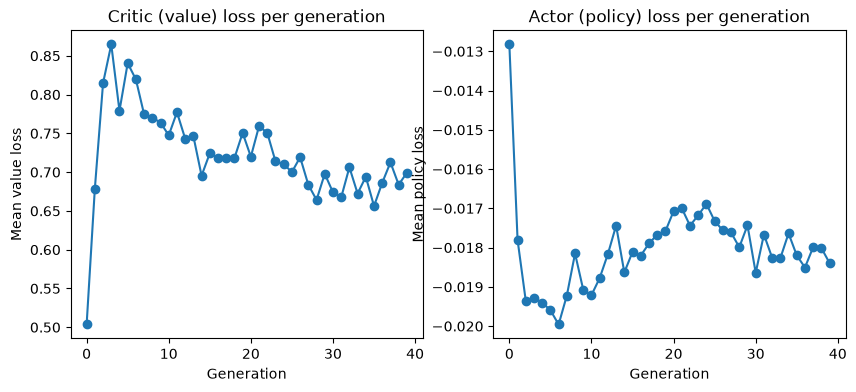

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(gens, metrics["value_loss"], marker="o")
ax1.set(xlabel="Generation", ylabel="Mean value loss", title="Critic (value) loss per generation")
ax2.plot(gens, metrics["policy_loss"], marker="o")
ax2.set(xlabel="Generation", ylabel="Mean policy loss", title="Actor (policy) loss per generation")
save(fig, "loss.png")

**Entropy.** Entropy measures how spread out the action probabilities are. It starts near the maximum, the dashed line where every action is equally likely, and should fall as the agent gets more confident. A slow drop is what we want. If it crashes toward zero early, the agent stopped exploring too soon, and raising `ENT_COEF` can help.

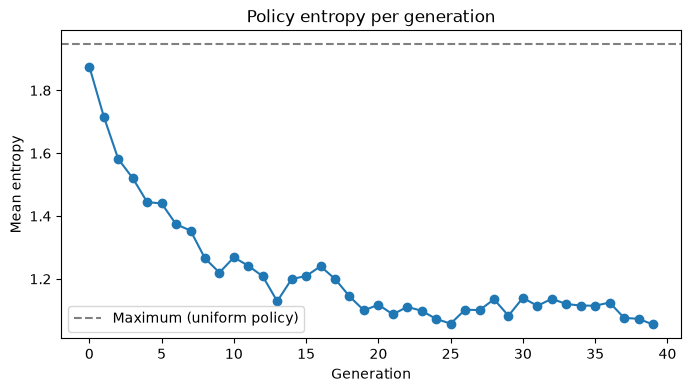

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["entropy"], marker="o")
ax.axhline(np.log(ppo_agent.action_space.n), color="gray", linestyle="--", label="Maximum (uniform policy)")
ax.set(xlabel="Generation", ylabel="Mean entropy", title="Policy entropy per generation")
ax.legend()
save(fig, "entropy.png")

**Average reward.** Both lines should climb as the agent gets better at picking enemies off. Blue shows AgileRL's evaluation during training. Orange shows our evaluation on the outro scenario, with the shaded band representing one standard deviation.

The band is wide because there's no time limit. One episode can end as soon as a demon gets through, and another can go on long enough for the kills to pile up. These rewards also include the damage penalty, so they come out a little lower than the kill count. Compare checkpoints within the same line.

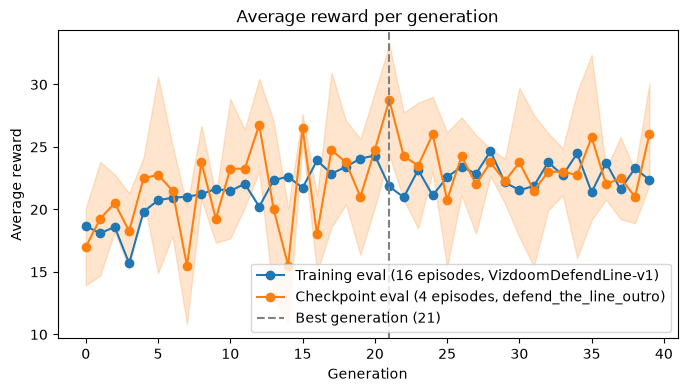

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["eval_fitness"], marker="o", label=f"Training eval ({INIT_HP['EVAL_LOOP'] * NUM_ENVS} episodes, {ENV_NAME})")
(line,) = ax.plot(gens, metrics["ckpt_eval_mean"], marker="o", label=f"Checkpoint eval ({EVAL_EPISODES} episodes, {SCENARIO_NAME})")
ax.fill_between(gens, metrics["ckpt_eval_mean"] - metrics["ckpt_eval_std"],
                metrics["ckpt_eval_mean"] + metrics["ckpt_eval_std"], color=line.get_color(), alpha=0.2)
ax.axvline(best_gen, color="gray", linestyle="--", label=f"Best generation ({best_gen})")
ax.set(xlabel="Generation", ylabel="Average reward", title="Average reward per generation")
ax.legend()
save(fig, "average_reward.png")

# Recording
To record the trained agent, we save ViZDoom's `.lmp` demos—which store only the inputs—and then replay them at 720p.


The Gymnasium wrapper doesn't expose demo recording, so `reset_with_lmp` temporarily replaces the reset function with one that starts a recording. `flush_lmp` begins the next episode so the file is actually written.

One gotcha: ViZDoom hangs if the demo path is longer than about 112 characters. We pass a path relative to the working directory, which keeps it short locally. Paths are longer on Colab when using Drive, so recording the best model still works, but `RECORD_CHECKPOINTS = "all"` can hang. Set `USE_DRIVE = False` if you want a video of every generation on Colab.

In [27]:
def reset_with_lmp(env, lmp_path):
    base = env.unwrapped
    orig_reset = base.reset

    def recorded_reset(*, seed=None, options=None):
        gymnasium.Env.reset(base, seed=seed)
        game_seed = int(
            base.np_random.integers(0, np.iinfo(np.uint32).max + 1, dtype=np.uint32)
        )
        base.game.set_seed(game_seed)
        if not base.game.is_running():
            base.game.init()
        # ViZDoom hangs if the demo path is longer than ~112 characters, so pass it relative to the working directory
        base.game.new_episode(os.path.relpath(lmp_path))
        base.state = base.game.get_state()
        return base._VizdoomEnv__collect_observations(), {}

    base.reset = recorded_reset
    try:
        return env.reset()
    finally:
        base.reset = orig_reset


def flush_lmp(env):
    env.unwrapped.game.new_episode()

We record `RECORD_EPISODES` episodes with the best checkpoint, or with every checkpoint when `RECORD_CHECKPOINTS` is set to `"all"`. Best-model videos go in `artifacts/video`; all others remain in the run folder. Existing best-model videos are cleared first so they don't get mixed with the current run.

In [28]:
assert RECORD_CHECKPOINTS in ("best", "all")
record_checkpoints = [best_checkpoint] if RECORD_CHECKPOINTS == "best" else checkpoints

for old in video_dir.glob("best_episode_*"):
    old.unlink()

In [29]:
record_env = make_env(scenario_cfg)
lmps = []
lmp_rewards = {}
for ckpt in record_checkpoints:
    gen = checkpoints.index(ckpt)
    out_dir, prefix = (video_dir, "best") if ckpt == best_checkpoint else (recording_dir, f"gen_{gen}")
    agent = load_agent(ckpt)
    for episode in range(RECORD_EPISODES):
        lmp = out_dir / f"{prefix}_episode_{episode}.lmp"
        obs, _ = reset_with_lmp(record_env, lmp)
        reward, _ = play(record_env, agent, obs)
        print(f"gen {gen:>2}  episode {episode}  reward={reward:.2f}  -> {lmp.name}")
        lmps.append(lmp)
        lmp_rewards[lmp] = reward
flush_lmp(record_env)
record_env.close()

/opt/miniconda3/lib/python3.13/site-packages/tensordict/_td.py:612: FutureWarning: TensorDict.to_module() is replacing an existing nn.Parameter in the destination module with a tensor leaf that is not an nn.Parameter. This historical behavior can remove the key from module.state_dict(). In tensordict v0.14, to_module() will preserve existing module parameter and buffer registrations by default. Pass preserve_module_state=False to keep the current replacement behavior, or preserve_module_state=True to opt in to the v0.14 behavior now.
  local_out = _set_tensor_dict(
/var/folders/y0/xcyn2fwj7gz4fr_vvrf29h1r0000gn/T/ipykernel_24380/426077457.py:2: UserWarning: Attribute rollout_buffer not found in checkpoint. Skipping.
  agent = PPO.load(str(path), device=device)


gen 21  episode 0  reward=28.01  -> best_episode_0.lmp
gen 21  episode 1  reward=31.01  -> best_episode_1.lmp
gen 21  episode 2  reward=23.01  -> best_episode_2.lmp


`lmp_to_mp4` replays each demo at 720p with the HUD enabled. The result looks much better than the 84x84 input used for training because we're replaying the actions in a fresh game rather than saving what the network saw. CRF 18, tuned for Doom's flat textures, keeps the files small enough for GitHub. Audio capture is silent on my Mac, so locally generated videos have no sound. Encoding takes a while because the encoder is configured to prioritize compression quality over speed.

In [30]:
SAMPLE_RATE = 22050
VIDEO_PARAMS = dict(  # x264 at constant quality: CRF 18 is visually lossless, and "animation" suits Doom's flat textures
    fps=35, codec="libx264", quality=None, macro_block_size=8,
    ffmpeg_params=["-crf", "18", "-preset", "veryslow", "-tune", "animation", "-movflags", "+faststart"],
)


def lmp_to_mp4(lmp_path):
    """Replay an .lmp at 720p with HUD and audio, and write it next to the .lmp as .mp4."""
    lmp_path = Path(lmp_path)
    mp4_path = lmp_path.with_suffix(".mp4")
    silent_path = lmp_path.with_name(lmp_path.stem + "_silent.mp4")
    wav_path = lmp_path.with_suffix(".wav")

    game = vzd.DoomGame()
    game.load_config(scenario_cfg)
    if DOOM_WAD:
        game.set_doom_game_path(DOOM_WAD)
    game.set_screen_resolution(vzd.ScreenResolution.RES_1280X720)
    game.set_render_hud(True)
    game.set_render_corpses(True)
    game.set_window_visible(False)
    game.set_audio_buffer_enabled(True)
    game.set_audio_sampling_rate(vzd.SamplingRate.SR_22050)
    game.set_audio_buffer_size(1)
    game.add_game_args("+snd_efx 0")
    game.set_mode(vzd.Mode.SPECTATOR)
    game.init()

    writer = imageio.get_writer(silent_path, **VIDEO_PARAMS)
    audio = []
    try:
        game.replay_episode(os.path.relpath(lmp_path))  # relative for the same path length limit as recording
        while not game.is_episode_finished():
            state = game.get_state()
            if state is not None:
                writer.append_data(np.transpose(state.screen_buffer, (1, 2, 0)))
                if state.audio_buffer is not None:
                    audio.append(state.audio_buffer)
            game.advance_action()
    finally:
        writer.close()
        game.close()

    audio = np.concatenate(audio) if audio else np.zeros(1)
    if not audio.any():  # no sound captured (e.g. on macOS): keep the silent video
        silent_path.replace(mp4_path)
        return mp4_path

    wavfile.write(wav_path, SAMPLE_RATE, audio)
    subprocess.run(
        [imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", silent_path, "-i", wav_path,
         "-c:v", "copy", "-c:a", "aac", "-shortest", mp4_path],
        check=True, capture_output=True,
    )
    silent_path.unlink()
    wav_path.unlink()
    return mp4_path

In [31]:
mp4s = [lmp_to_mp4(lmp) for lmp in lmps]
mp4s

[PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-line-ppo-AgileRL/artifacts/video/best_episode_0.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-line-ppo-AgileRL/artifacts/video/best_episode_1.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-line-ppo-AgileRL/artifacts/video/best_episode_2.mp4')]

For a quick preview, the highest-scoring episode is converted to a deliberately small GIF that plays directly in the notebook and on GitHub. The full-resolution MP4s remain in `artifacts/video`.

best_episode_1.gif  reward=31.01  (2.1 MB)


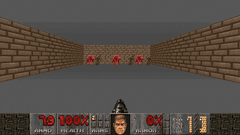

In [32]:
GIF_WIDTH = 240
GIF_FPS = 10


def mp4_to_gif(mp4_path):
    """Write a small GIF next to an MP4, with a palette built from the video so the colors hold up."""
    gif_path = Path(mp4_path).with_suffix(".gif")
    vf = (
        f"fps={GIF_FPS},scale={GIF_WIDTH}:-1:flags=lanczos,split[a][b];"
        "[a]palettegen=max_colors=128:stats_mode=diff[p];[b][p]paletteuse=dither=bayer:bayer_scale=5:diff_mode=rectangle"
    )
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", mp4_path, "-vf", vf, gif_path], check=True, capture_output=True)
    return gif_path


best_mp4 = max(
    (m for m in mp4s if m.name.startswith("best")),
    key=lambda m: lmp_rewards[m.with_suffix(".lmp")],
)
best_gif = mp4_to_gif(best_mp4)
print(f"{best_gif.name}  reward={lmp_rewards[best_mp4.with_suffix('.lmp')]:.2f}  ({best_gif.stat().st_size / 2**20:.1f} MB)")
display(Image(filename=str(best_gif)))

# Results
A short summary of the run, also saved to `artifacts/results.json` so runs are easy to compare later.

In [33]:
results = {
    "run": run_dir.name,
    "scenario": SCENARIO_NAME,
    "iwad": IWAD_NAME,
    "best_checkpoint": best_checkpoint.name,
    "best_generation": best_gen,
    "best_steps": int(metrics.loc[best_gen, "steps"]),
    "generations": len(checkpoints),
    "checkpoint_eval_mean": round(float(metrics.loc[best_gen, "ckpt_eval_mean"]), 4),
    "checkpoint_eval_std": round(float(metrics.loc[best_gen, "ckpt_eval_std"]), 4),
    "checkpoint_eval_rewards": [round(float(r), 4) for r in eval_rewards[best_gen]],
    "best_video": [str(m.relative_to(experiment_dir)) for m in mp4s if m.name.startswith("best")],
    "best_gif": str(best_gif.relative_to(experiment_dir)),
}
results_path.write_text(json.dumps(results, indent=2))
pd.Series(results, name="value").to_frame()

,value
run,run-20261020_195949
scenario,defend_the_line_outro
iwad,DOOM2.WAD
best_checkpoint,PPO_0_1126400.pt
best_generation,21
best_steps,1126400
generations,40
checkpoint_eval_mean,28.76
checkpoint_eval_std,4.4371
checkpoint_eval_rewards,"[31.01, 22.01, 34.01, 28.01]"


# Wrapping Up

This was a fun notebook, PPO has always been one of my favorite RL algorithms and it was fun to see how well our agent did at holding the line! Overall I think our agent did pretty well in this last stand scenario, and I'm excited to try some harder challenges! Like perhaps more complex scenarios with full range of movement! But that's for a future notebook.

Happy Coding!